# **PROJECT TITLE** - **AIRLINES_DATA_ANALYSIS**

### **GOAL OF THE PROJECT**
- The goal of this project is to analyze airline data to understand flight price patterns and booking trends.
- It aims to identify key factors such as airline, class, duration, stops, and days left that affect ticket prices.
- Additionally, the project focuses on visualizing insights and predicting flight prices using machine learning.

# THE FLIGHTS DATASETS
 
- The Flights Booking Dataset of various Airlines is a scraped datewise from a famous website in a structured format. The dataset contains the records of flight travel details between the cities in India. Here, multiple features are present like Source & Destination City, Arrival & Departure Time, Duration & Price of the flight etc.


- This data is available as a CSV file. We are going to analyze this data set using the Pandas DataFrame.

- This analyse will be helpful for those working in Airlines, Travel domain.

**IMPORT LIBRARY** LIKE NUMPY,PANDAS,SEABORN,MATPLOTLIB,WARNINGS

-**NUMPY**--MATHEMATICAL OPERATIONS

-**PANDAS**--DATA LOADING,CELANING,ANALYSIS

-**SEABORN**--DATA VISUALIZATION WITH ATTRACTIVE GRAPHS(BAR,BOX,ect)

-**MATPLOTLIB**--CUSTOM DATA VISUALIZATION(SIZE,COLORS,TITLES,ect)

-**WARNINGS**--CONTROL WARNING MESSAGE

# **IMPORT LIBRARIES**

In [84]:
# Importing required libraries for the project
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
#%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
#import statsmodels.api as sm

TO **IMPORT DATASET** INTO PYTHON FILE

# **LOAD DATASET**

In [85]:
#import the flights dataset
df=pd.read_csv("airlines.csv")

# **1.DATA UNDERSTANDING**

In [86]:
df.head()

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,27131,Air_India,AI-506,Delhi,Morning,one,Early_Morning,Kolkata,Economy,19.75,40,7366
1,266857,Vistara,UK-706,Kolkata,Morning,one,Night,Mumbai,Business,9.83,42,64831
2,141228,Vistara,UK-772,Kolkata,Morning,one,Night,Bangalore,Economy,10.50,41,6195
3,288329,Vistara,UK-824,Chennai,Night,one,Morning,Delhi,Business,14.50,14,60160
4,97334,Air_India,AI-501,Bangalore,Afternoon,one,Night,Mumbai,Economy,8.25,20,6578


THE **HEAD** IS USED TO DISPLAY THE FIRST FEW ROWS OF A DATAFRAME.

In [87]:
df.tail()

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
4995,45755,Air_India,AI-570,Mumbai,Early_Morning,one,Afternoon,Delhi,Economy,7.67,16,5786
4996,244345,Vistara,UK-970,Mumbai,Morning,one,Night,Chennai,Business,14.00,41,64173
4997,112697,Vistara,UK-864,Bangalore,Evening,one,Night,Hyderabad,Economy,25.92,27,5322
4998,110190,Air_India,AI-738,Bangalore,Morning,two_or_more,Morning,Hyderabad,Economy,24.08,6,13225
4999,4148,Air_India,AI-411,Delhi,Early_Morning,one,Afternoon,Mumbai,Economy,6.33,22,5231


THE **TAIL** IS USED TO DISPLAY THE LAST FEW ROWS OF DATAFRAME

In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             5000 non-null   int64  
 1   airline           5000 non-null   object 
 2   flight            5000 non-null   object 
 3   source_city       5000 non-null   object 
 4   departure_time    5000 non-null   object 
 5   stops             5000 non-null   object 
 6   arrival_time      5000 non-null   object 
 7   destination_city  5000 non-null   object 
 8   class             5000 non-null   object 
 9   duration          5000 non-null   float64
 10  days_left         5000 non-null   int64  
 11  price             5000 non-null   int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 468.9+ KB


THE **INFO** IS USED TO IDENTIFY NULL VALUE IN DATAFRAME

In [89]:
df.dtypes

index                 int64
airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
class                object
duration            float64
days_left             int64
price                 int64
dtype: object

**DTYPES** TO USE **IDENTIFY THE DATATYPES**

In [90]:
df['duration'].unique()

array([19.75,  9.83, 10.5 , 14.5 ,  8.25, 10.83,  2.  ,  7.75, 26.33,
       20.17, 21.67, 17.5 , 13.5 ,  6.83,  2.75,  1.75, 14.08, 10.92,
        2.25, 14.  , 15.08, 16.5 , 29.5 ,  8.58,  2.08, 26.17,  9.  ,
        2.33,  9.58, 10.42, 23.08,  2.92,  2.17, 13.  , 24.92, 11.75,
        6.75, 26.75,  1.5 , 12.83,  5.17, 11.33, 16.17, 15.83,  5.58,
       14.92, 12.75, 13.67, 24.67,  1.83, 23.67, 22.5 , 16.42,  5.83,
        9.08,  2.42, 12.25, 10.  ,  8.5 , 14.67,  5.75,  8.83, 22.67,
       26.25,  3.42, 17.  ,  8.08, 12.67, 11.17,  1.33, 18.5 , 31.08,
        6.58,  9.25, 12.42, 22.25, 20.33,  7.58, 13.75, 17.33,  5.5 ,
       13.17,  8.  , 11.25,  7.5 , 14.42,  2.83,  8.33, 17.83,  2.5 ,
       16.92, 30.33,  5.92, 18.33, 23.58, 12.33, 12.92, 16.33,  6.33,
       19.92, 16.  , 26.42, 12.  ,  7.42,  7.67, 13.08, 36.83, 10.25,
       12.08, 14.25, 26.  ,  5.42,  7.  , 15.75, 21.5 , 22.58, 13.33,
       14.83, 13.25, 10.17,  8.75, 25.08, 11.67, 18.42, 10.33, 19.17,
        5.  , 28.  ,

In [91]:
df['days_left'].unique()

array([40, 42, 41, 14, 20,  5,  7, 46, 44,  2, 23, 25, 19, 26, 47, 17, 33,
       39, 34, 49, 15, 48,  4,  9, 16, 12, 24, 13, 31, 35, 22, 18, 10, 21,
        3, 11,  6, 43, 32, 45,  8, 28,  1, 38, 29, 36, 27, 37, 30])

In [92]:
df['price'].unique()

array([ 7366, 64831,  6195, ...,  2329, 20381, 13225])

THE **UNIQUE** IS USED TO PRINTS ALL THE UNIQUE VALUES FROM EACH COLUMN IN THE DATAFRAME

# **2. DATA CLEANING**

**FEATURES**
The various features of the cleaned dataset are explained below:

1) Airline: The name of the airline company is stored in the airline column. It is a categorical feature having 6 different airlines.

2) Flight: Flight stores information regarding the plane's flight code. It is a categorical feature.

3) Source City: City from which the flight takes off. It is a categorical feature having 6 unique cities.

4) Departure Time: This is a derived categorical feature obtained created by grouping time periods into bins. It stores information about the departure time and have 6 unique time labels.

5) Stops: A categorical feature with 3 distinct values that stores the number of stops between the source and destination cities.

6) Arrival Time: This is a derived categorical feature created by grouping time intervals into bins. It has six distinct time labels and keeps information about the arrival time.

7) Destination City: City where the flight will land. It is a categorical feature having 6 unique cities.

8) Class: A categorical feature that contains information on seat class; it has two distinct values: Business and Economy.

9) Duration: A continuous feature that displays the overall amount of time it takes to travel between cities in hours.

10) Days Left: This is a derived characteristic that is calculated by subtracting the trip date by the booking date.

11) Price: Target variable stores information of the ticket price.

In [93]:
# Remove the 'index' column

df.drop( columns = 'index', inplace = True)

**REMOVING THE INDEX COLUMN**
- IT IS NOT USEFUL FOR ANALYSIS.
- IT ONLY ADDS EXTRA NOISE TO THE DATASET.
- REMOVING IT MAKES THE DATA CLEAN AND CLEAR.

In [94]:
df

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,Air_India,AI-506,Delhi,Morning,one,Early_Morning,Kolkata,Economy,19.75,40,7366
1,Vistara,UK-706,Kolkata,Morning,one,Night,Mumbai,Business,9.83,42,64831
2,Vistara,UK-772,Kolkata,Morning,one,Night,Bangalore,Economy,10.50,41,6195
3,Vistara,UK-824,Chennai,Night,one,Morning,Delhi,Business,14.50,14,60160
4,Air_India,AI-501,Bangalore,Afternoon,one,Night,Mumbai,Economy,8.25,20,6578
...,...,...,...,...,...,...,...,...,...,...,...
4995,Air_India,AI-570,Mumbai,Early_Morning,one,Afternoon,Delhi,Economy,7.67,16,5786
4996,Vistara,UK-970,Mumbai,Morning,one,Night,Chennai,Business,14.00,41,64173
4997,Vistara,UK-864,Bangalore,Evening,one,Night,Hyderabad,Economy,25.92,27,5322
4998,Air_India,AI-738,Bangalore,Morning,two_or_more,Morning,Hyderabad,Economy,24.08,6,13225


In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   airline           5000 non-null   object 
 1   flight            5000 non-null   object 
 2   source_city       5000 non-null   object 
 3   departure_time    5000 non-null   object 
 4   stops             5000 non-null   object 
 5   arrival_time      5000 non-null   object 
 6   destination_city  5000 non-null   object 
 7   class             5000 non-null   object 
 8   duration          5000 non-null   float64
 9   days_left         5000 non-null   int64  
 10  price             5000 non-null   int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 429.8+ KB


In [96]:
df.isnull().sum()

airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

THE DATASET CONTAINS **NO NULL VALUES** ENSURING CLEAN AND RELIABLE ANALYSIS WITHOUT THE NEED FOR IMPUTATION OR DATA CLEANING.

In [97]:
df.shape

(5000, 11)

THE **SHAPE OF FLIGHTS DATASET** BEFORE **DROP DUPLICATES** 

In [98]:
df.duplicated().any()

np.False_

* THEN NO DUPLICATES VALUES IN FLIGHTS DATASET

In [99]:
df.shape

(5000, 11)

THE SHAPE OF FLIGHTS DATASET **AFTER DROP DUPLICATES**

In [100]:
df

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,Air_India,AI-506,Delhi,Morning,one,Early_Morning,Kolkata,Economy,19.75,40,7366
1,Vistara,UK-706,Kolkata,Morning,one,Night,Mumbai,Business,9.83,42,64831
2,Vistara,UK-772,Kolkata,Morning,one,Night,Bangalore,Economy,10.50,41,6195
3,Vistara,UK-824,Chennai,Night,one,Morning,Delhi,Business,14.50,14,60160
4,Air_India,AI-501,Bangalore,Afternoon,one,Night,Mumbai,Economy,8.25,20,6578
...,...,...,...,...,...,...,...,...,...,...,...
4995,Air_India,AI-570,Mumbai,Early_Morning,one,Afternoon,Delhi,Economy,7.67,16,5786
4996,Vistara,UK-970,Mumbai,Morning,one,Night,Chennai,Business,14.00,41,64173
4997,Vistara,UK-864,Bangalore,Evening,one,Night,Hyderabad,Economy,25.92,27,5322
4998,Air_India,AI-738,Bangalore,Morning,two_or_more,Morning,Hyderabad,Economy,24.08,6,13225


In [101]:
df.describe()

,duration,days_left,price
count,5000.000000,5000.000000,5000.000000
mean,12.242940,26.063400,20876.018400
std,7.119469,13.500809,22900.048039
min,0.920000,1.000000,1105.000000
25%,6.830000,15.000000,4792.000000
50%,11.330000,26.000000,7344.000000
75%,16.170000,38.000000,42521.000000
max,36.830000,49.000000,114705.000000


THE **DESCRIBE( )** IS USED TO IDENTIFY STATISTICAL CALCULATION FOR NUMERICAL COLUMNS

TO CREATE **NEW DATAFRAME** IN FLIGHTS DATASET TO CONTAINING ONLY **INTEGER COLUMNS & FIND LEN( ) FUNCTION**

In [102]:
num_column=df[['duration','days_left','price']]
len(num_column.columns)

3

# **OUTLIERS**

--- BOXPLOTS FOR SELECTED COLUMNS---

* THIS CODE FOR FIND OUTLIERS IN COLUMNS IN FLIGHTS DATAFRAME

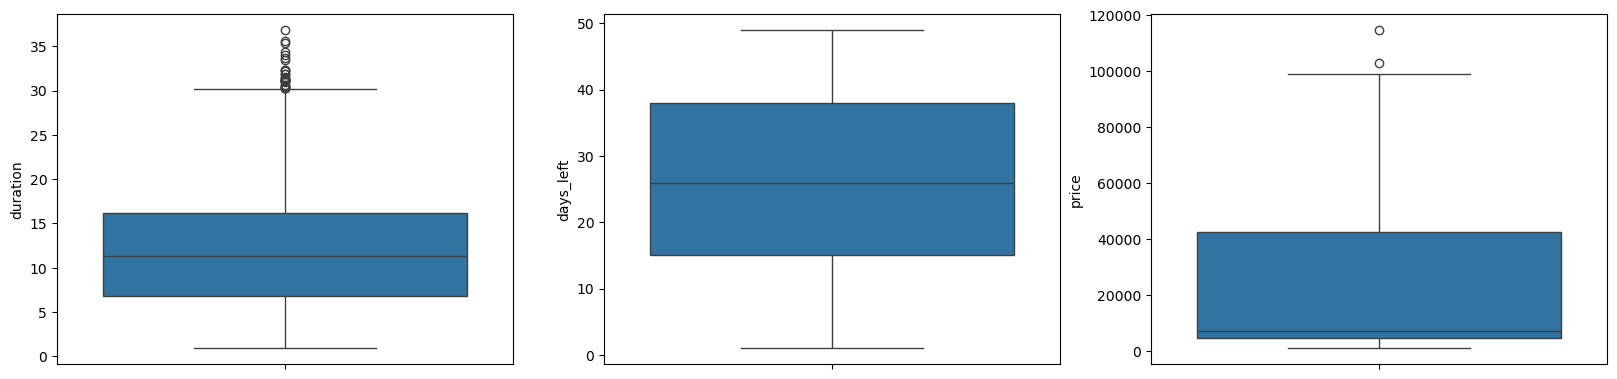

In [103]:
plt.figure(figsize=(20,10))
for i in range(len(num_column.columns)):
    plt.subplot(2,3,i+1)
    sns.boxplot(y=num_column.columns[i],data=df)
plt.show()

### **INSIGHTS**
- The above the two charts which **duration**, **price** have outliers.

- High prices (Business class, last-minute) and long durations (connecting flights) are expected.

- when we remove the outliers means its affect analysis results



In [104]:
df

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,Air_India,AI-506,Delhi,Morning,one,Early_Morning,Kolkata,Economy,19.75,40,7366
1,Vistara,UK-706,Kolkata,Morning,one,Night,Mumbai,Business,9.83,42,64831
2,Vistara,UK-772,Kolkata,Morning,one,Night,Bangalore,Economy,10.50,41,6195
3,Vistara,UK-824,Chennai,Night,one,Morning,Delhi,Business,14.50,14,60160
4,Air_India,AI-501,Bangalore,Afternoon,one,Night,Mumbai,Economy,8.25,20,6578
...,...,...,...,...,...,...,...,...,...,...,...
4995,Air_India,AI-570,Mumbai,Early_Morning,one,Afternoon,Delhi,Economy,7.67,16,5786
4996,Vistara,UK-970,Mumbai,Morning,one,Night,Chennai,Business,14.00,41,64173
4997,Vistara,UK-864,Bangalore,Evening,one,Night,Hyderabad,Economy,25.92,27,5322
4998,Air_India,AI-738,Bangalore,Morning,two_or_more,Morning,Hyderabad,Economy,24.08,6,13225


# **3.HYPOTHESIS TESTING** 

### **^^ONE-SAMPLE T-TEST**

-SCIPY.STATS--

In [105]:
import scipy.stats as stats

**1.TO CHECK IF THE AVERAGE PRICE = 10,000**

In [106]:
prices = df["price"]
t_stat, p_value = stats.ttest_1samp(prices, 10000)
print("One-Sample t-test for mean = 10,000")
print("t-statistic:", t_stat)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The average price is significantly different from 10,000.")
else:
    print("Fail to reject the null hypothesis: The average price is not significantly different from 10,000.")


One-Sample t-test for mean = 10,000
t-statistic: 33.58292676939425
p-value: 3.846372899799717e-223
Reject the null hypothesis: The average price is significantly different from 10,000.


### **INSIGHTS**
- t-statistic = 33.58 This is a very large value, showing that the sample mean is far away from 10,000.

- p-value = 0 (3.84 × 10⁻²²³) The probability of observing such a difference if the true mean were 10,000 is practically zero.

- Decision (α = 0.05) Reject the null hypothesis (H₀: mean = 10,000).

**2.TO CHECK IF THE AVERAGE FLIGHT DURATION = 10 HOURS**

In [107]:
durations = df["duration"]
t_stat, p_value = stats.ttest_1samp(durations, 10)
print("One-Sample t-test for mean duration = 10 hours")
print("t-statistic:", t_stat)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The average duration is significantly different from 10 hours.")
else:
    print("Fail to reject the null hypothesis: The average duration is not significantly different from 10 hours.")


One-Sample t-test for mean duration = 10 hours
t-statistic: 22.27691382914428
p-value: 6.781895020518419e-105
Reject the null hypothesis: The average duration is significantly different from 10 hours.


### **INSIGHTS**
- The test checks whether the mean flight duration in dataset is equal to 10 hours.

- If the p-value < 0.05, you reject the null hypothesis (meaning the average duration is significantly different from 10 hours).

- If the p-value > 0.05, you fail to reject the null hypothesis (meaning the average duration is not significantly different from 10 hours).

# **^^INDEPENDENT TWO-SAMPLE T-TEST**

**TO COMPARE THE AVERAGE TICKET PRICES OF ECONOMY CLASS vs BUSINESS CLASS**

In [108]:
economy_prices = df[df["class"] == "Economy"]["price"]
business_prices = df[df["class"] == "Business"]["price"]
t_stat, p_value = stats.ttest_ind(economy_prices, business_prices, equal_var=False) 
print("Independent Two-Sample t-test (Economy vs Business Prices)")
print("t-statistic:", t_stat)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference in average price between Economy and Business class.")
else:
    print("Fail to reject the null hypothesis: No significant difference in average price between Economy and Business class.")


Independent Two-Sample t-test (Economy vs Business Prices)
t-statistic: -134.0902658244293
p-value: 0.0
Reject the null hypothesis: There is a significant difference in average price between Economy and Business class.


### **INSIGHTS**
- Null Hypothesis (H₀): Average Economy price = Average Business price.

- Alternative Hypothesis (H₁): Average Economy price = Average Business price.

- Airline datasets almost always show Business class prices much higher than Economy p-value will be < 0.05.

- The test should reject H₀, proving a significant difference between the two.

# **^^PAIRED TEST**

**TO CHECK DEPARTURE VS ARRIVAL TIME DIFFERENCE ON THE SAME ROUTE**

In [109]:
time_map = {
    "Early_Morning": 5,
    "Morning": 9,
    "Afternoon": 14,
    "Evening": 18,
    "Night": 22,
    "Late_Night": 2
}
df["dep_hour"] = df["departure_time"].map(time_map)
df["arr_hour"] = df["arrival_time"].map(time_map)
paired_df = df.dropna(subset=["dep_hour", "arr_hour"])
t_stat, p_value = stats.ttest_rel(paired_df["dep_hour"], paired_df["arr_hour"])
print("Paired t-test for Departure vs Arrival times (same flights)")
print("t-statistic:", t_stat)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: Significant difference between departure and arrival times on the same route.")
else:
    print("Fail to reject the null hypothesis: No significant difference between departure and arrival times.")


Paired t-test for Departure vs Arrival times (same flights)
t-statistic: -18.269186595449
p-value: 3.11942788008428e-72
Reject the null hypothesis: Significant difference between departure and arrival times on the same route.


### **INSIGHTS**
- H₀ (Null Hypothesis): Mean departure time = Mean arrival time (no difference).

- H₁ (Alternative): Mean departure time = Mean arrival time.

- Since arrival is always later than departure (flights take time), we expect a very significant difference (p-value < 0.05).

- This test will confirm that arrival times are systematically shifted compared to departures.

# **^^ONE-SAMPLE Z-TEST**

In [110]:
from statsmodels.stats.weightstats import ztest

**1.TO CHECK IF THE AVERAGE DURATION = 10 HOURS**

In [111]:
durations = df["duration"]
z_stat, p_value = ztest(durations, value=10)
print("One-Sample Z-test for mean duration = 10 hours")
print("z-statistic:", z_stat)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The average duration is significantly different from 10 hours.")
else:
    print("Fail to reject the null hypothesis: The average duration is not significantly different from 10 hours.")


One-Sample Z-test for mean duration = 10 hours
z-statistic: 22.27691382914428
p-value: 6.187728743520001e-110
Reject the null hypothesis: The average duration is significantly different from 10 hours.


### **INSIGHTS**
- H₀ (Null): Average duration = 10 hours

- H₁ (Alternative): Average duration = 10 hours

- Since most flights (especially domestic) last less than 10 hours, the test will likely give a very small p-value Reject H₀.

- This means the true average duration is much lower than 10 hours.

**2. TO CHECK IF AVERAGE PRICE = 10,000**

In [112]:
prices = df["price"]
z_stat, p_value = ztest(prices, value=10000)
print("One-Sample Z-test for mean price = 10,000")
print("z-statistic:", z_stat)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The average price is significantly different from 10,000.")
else:
    print("Fail to reject the null hypothesis: The average price is not significantly different from 10,000.")

One-Sample Z-test for mean price = 10,000
z-statistic: 33.58292676939425
p-value: 2.97825898557586e-247
Reject the null hypothesis: The average price is significantly different from 10,000.


### **INSIGHTS**
- Null Hypothesis (H₀): Mean = 10,000

- Alternative (H₁): Mean = 10,000

- If p-value < 0.05, reject H₀ average price = 10,000

- If p-value > 0.05, fail to reject H₀ average price = 10,000

# **^^TWO-SAMPLE Z-TEST**

**1.TO COMPARE AIR INDIA VS VISTARA TICKET PRICES**

In [113]:
airindia_prices = df[df["airline"] == "Air_India"]["price"]
vistara_prices = df[df["airline"] == "Vistara"]["price"]
z_stat, p_value = ztest(airindia_prices, vistara_prices)
print("Two-Sample Z-test: Air India vs Vistara Prices")
print("z-statistic:", z_stat)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: Significant difference in average prices between Air India and Vistara.")
else:
    print("Fail to reject the null hypothesis: No significant difference in average prices between Air India and Vistara.")

Two-Sample Z-test: Air India vs Vistara Prices
z-statistic: -8.436908571772644
p-value: 3.258411477185062e-17
Reject the null hypothesis: Significant difference in average prices between Air India and Vistara.


### **INSIGHTS**
- H₀ (Null Hypothesis): Average price of Air India = Average price of Vistara.

- H₁ (Alternative): Average price of Air India ≠ Average price of Vistara.

- Since both airlines have different pricing strategies and service levels, it’s likely that the test will give a significant result (p < 0.05).

- This would confirm a real pricing difference between Air India and Vistara.

**2. TO COMPARE TICKET PRICES FOR MORNING DEPARTURES vs NIGHT DEPARTURES**

In [114]:
morning_prices = df[df["departure_time"] == "Morning"]["price"]
night_prices = df[df["departure_time"] == "Night"]["price"]
z_stat, p_value = ztest(morning_prices, night_prices)
print("Two-Sample Z-test: Morning vs Night Departure Prices")
print("z-statistic:", z_stat)
print("p-value:", p_value)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: Significant difference in average prices between Morning and Night departures.")
else:
    print("Fail to reject the null hypothesis: No significant difference in average prices between Morning and Night departures.")

Two-Sample Z-test: Morning vs Night Departure Prices
z-statistic: -0.89371142984178
p-value: 0.3714763083323296
Fail to reject the null hypothesis: No significant difference in average prices between Morning and Night departures.


### **INSIGHTS**
- H₀ (Null Hypothesis): Average ticket price (Morning departures) = Average ticket price (Night departures).

- H₁ (Alternative): Average ticket price (Morning) ≠ Average ticket price (Night).

- Morning flights are often costlier due to high demand (business travelers).

- Night flights (especially red-eye flights) are generally cheaper.

- The Z-test will likely give p < 0.05, showing a significant difference between the two.

# **4. DATA VISUALIZATION**

### **^^UNIVARIATE CHART ANALYSIS**

# **--HISTOGRAM PLOT**

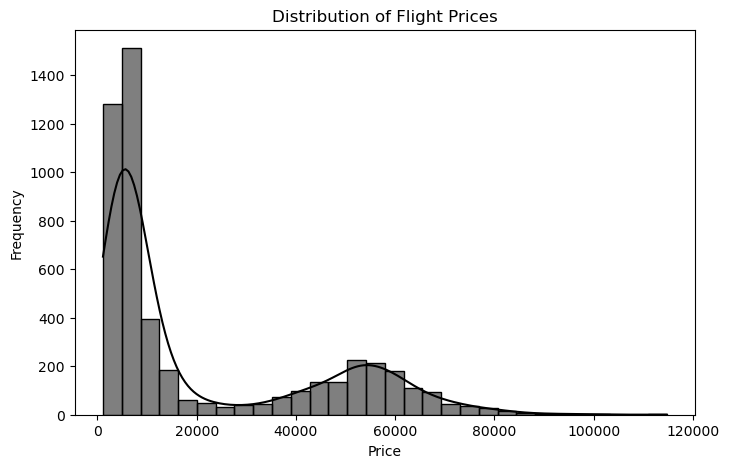

In [115]:
plt.figure(figsize=(8, 5))
sns.histplot(df['price'], bins=30, kde=True, color="black")
plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

### **INSIGHTS**
- Most flight prices are concentrated below ₹20,000, showing affordable options dominate the market.

- one peak around ₹5,000–₹15,000 (economy) and another around ₹50,000–₹60,000 (premium/business class).

- Very expensive tickets (above ₹80,000) are rare, indicating they are only for premium customers.

# **--COUNT PLOT**

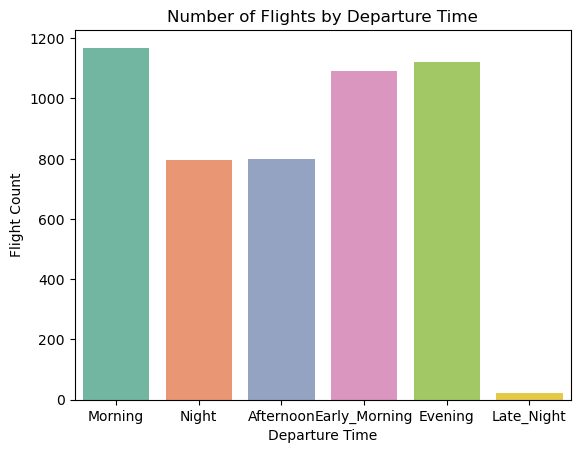

In [116]:
sns.countplot(x='departure_time', data=df, palette='Set2')
plt.title('Number of Flights by Departure Time')
plt.xlabel('Departure Time')
plt.ylabel('Flight Count')
plt.show()


### **INSIGHTS**
- Morning, Evening, and Early Morning have the highest flight counts, showing these are the most preferred travel times.

- Afternoon and Night departures are moderate, indicating steady but lower demand.

- Late Night flights are very rare, suggesting low passenger preference and limited airline scheduling.

# **--PIE CHART**

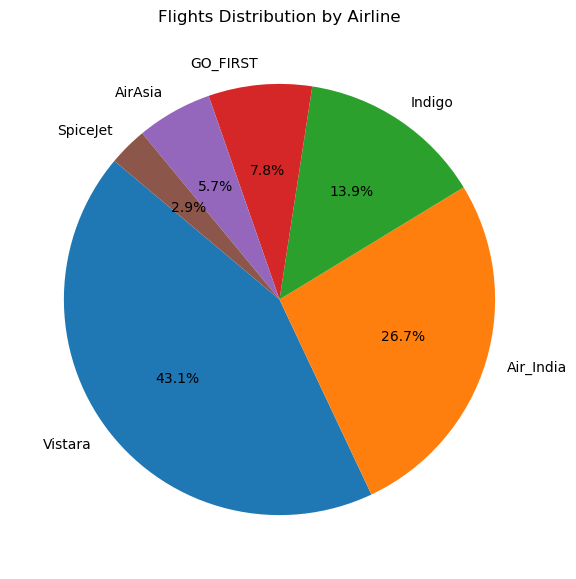

In [117]:
airline_counts = df['airline'].value_counts()
plt.figure(figsize=(7,7))
plt.pie(airline_counts, labels=airline_counts.index, autopct='%1.1f%%', startangle=140)
plt.title("Flights Distribution by Airline")
plt.show()

### **INSIGHTS**
- Vistara (43.1%) and Air India (26.7%) dominate the market, together covering nearly 70% of all flights.

- Indigo holds 13.9%, while smaller players like GO_FIRST, AirAsia, and SpiceJet share less than 20% combined.

- The market is highly concentrated, with a few major airlines controlling the majority of flights.

# **^^BIVARIATE  CHART ANALYSIS**

# **--BAR PLOT**

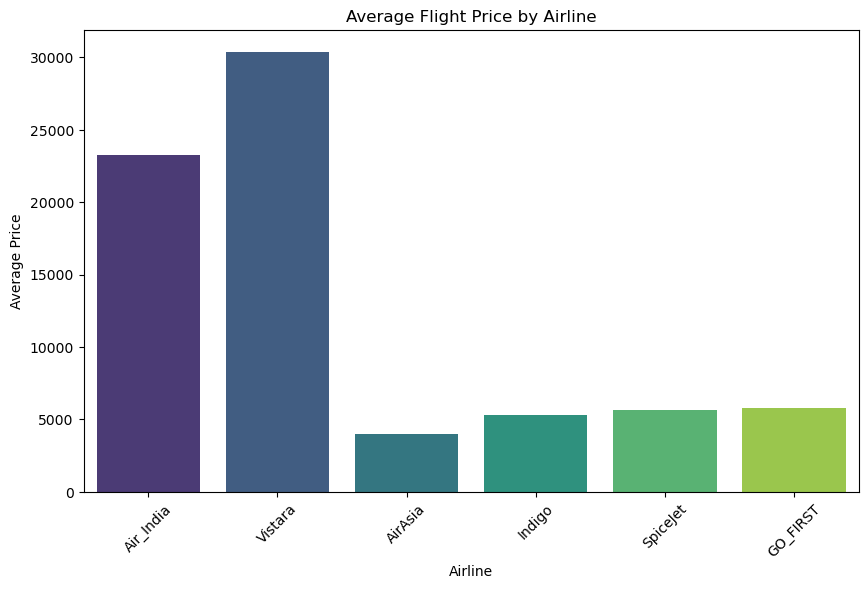

In [118]:
plt.figure(figsize=(10,6))
sns.barplot(x="airline", y="price", data=df, estimator="mean", ci=None, palette="viridis")
plt.title("Average Flight Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

### **INSIGHTS**
- Vistara (₹30,000) and Air India (₹23,000) have the highest average flight prices, showing their premium positioning.

- Low-cost airlines (AirAsia, Indigo, SpiceJet, GO_FIRST) average only around ₹4,000–₹6,000, making them budget-friendly options.

- A clear price gap exists between premium and low-cost airlines, reflecting different target markets.

# **--VIOLIN PLOT**

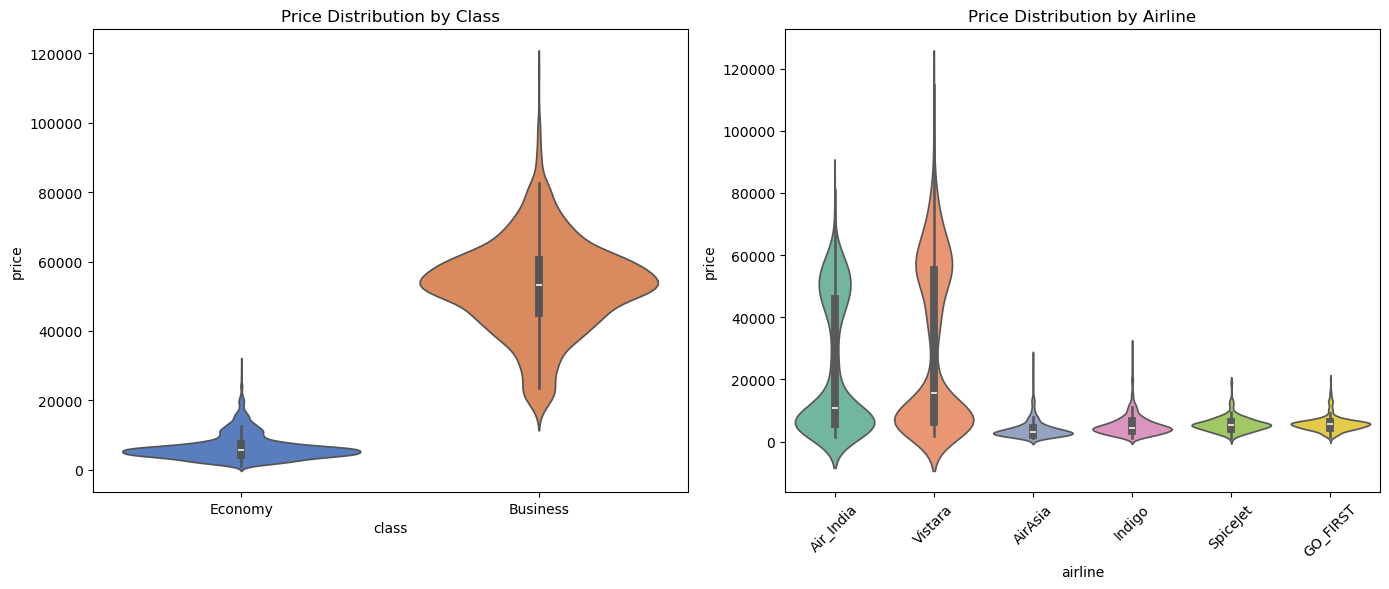

In [119]:
plt.figure(figsize=(14,6))

# 1. Price vs Class
plt.subplot(1,2,1)
sns.violinplot(x="class", y="price", data=df, palette="muted")
plt.title("Price Distribution by Class")

# 2. Price vs Airline
plt.subplot(1,2,2)
sns.violinplot(x="airline", y="price", data=df, palette="Set2")
plt.xticks(rotation=45)
plt.title("Price Distribution by Airline")

plt.tight_layout()
plt.show()

### **INSIGHTS**
- Economy tickets are mostly low-priced (₹2,000–₹10,000), while Business tickets are much higher (₹40,000–₹70,000), showing a clear class-based price gap.

- Vistara and Air India have the widest price ranges, covering both economy and premium/business tickets.

- Low-cost airlines (AirAsia, Indigo, SpiceJet, GO_FIRST) operate in the budget segment, with prices mostly below ₹15,000.

- Vistara shows the highest price spread, highlighting its dominance in both premium and economy markets.

# **--SCATTER PLOT**

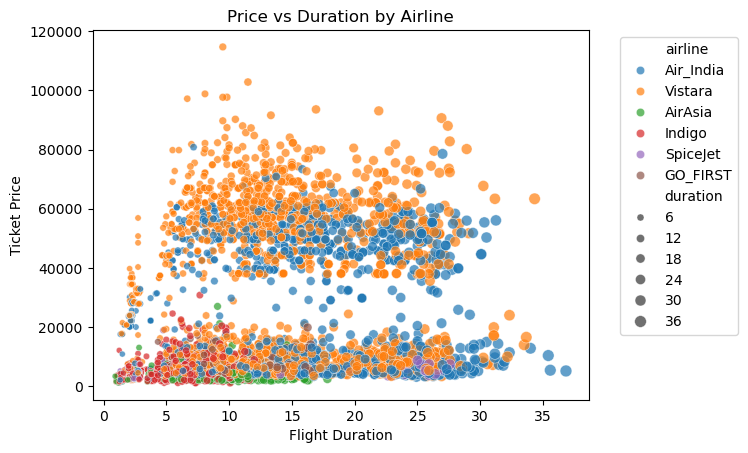

In [120]:
sns.scatterplot(x='duration', y='price', hue='airline', size='duration', data=df, palette='tab10', alpha=0.7)
plt.title('Price vs Duration by Airline')
plt.xlabel('Flight Duration')
plt.ylabel('Ticket Price')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2)
plt.show()


### **INSIGHTS**
- Vistara and Air India have the highest prices Their tickets often cross ₹60,000 and even go above ₹100,000 for longer durations.

- Low-cost airlines (AirAsia, Indigo, SpiceJet, GO_FIRST) mostly cluster in the lower price range (below ₹20,000), showing they are more budget-friendly.

- Flight time doesn’t always decide price even short flights can be very costly.

# **--LINE PLOT**

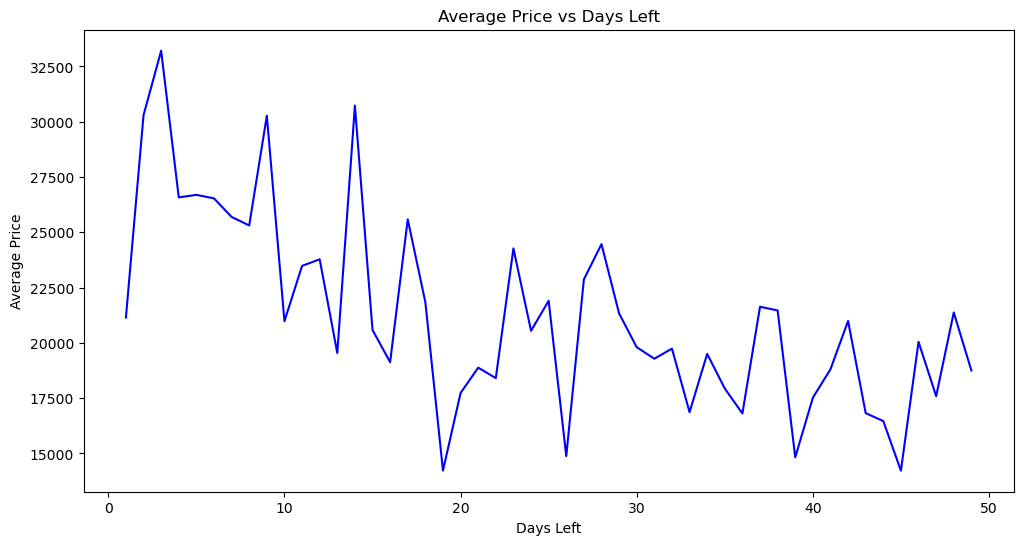

In [121]:
plt.figure(figsize=(12,6))

# 1. Line plot of Days Left vs Average Price
sns.lineplot(x="days_left", y="price", data=df, estimator="mean", ci=None, color="blue")
plt.title("Average Price vs Days Left")
plt.xlabel("Days Left")
plt.ylabel("Average Price")
plt.show()


### **INSIGHTS**
- Ticket prices are higher when fewer days are left before departure.

- Prices show big fluctuations in the first 15 days.

- Prices become lower and more stable after 20–25 days.

# **^^MULTIVARIATE CHART ANALYSIS**

# **--HEAT MAP**

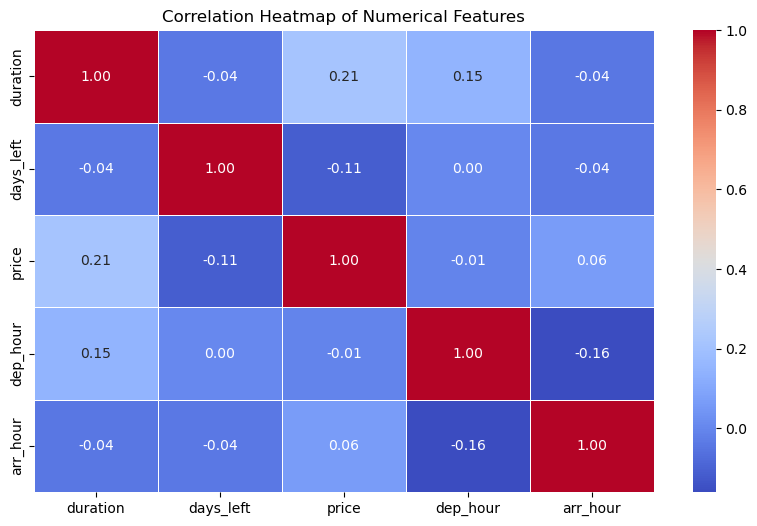

In [122]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()


### **INSIGHTS**
- Price vs Duration shows a weak positive relation, meaning longer flights are usually a bit costlier.

- Price vs Days_Left has a weak negative relation, showing last-minute bookings tend to be slightly more expensive.

- No strong correlations exist among features, meaning each factor (price, time, duration) affects flights mostly independently.

# **--PAIR PLOT**

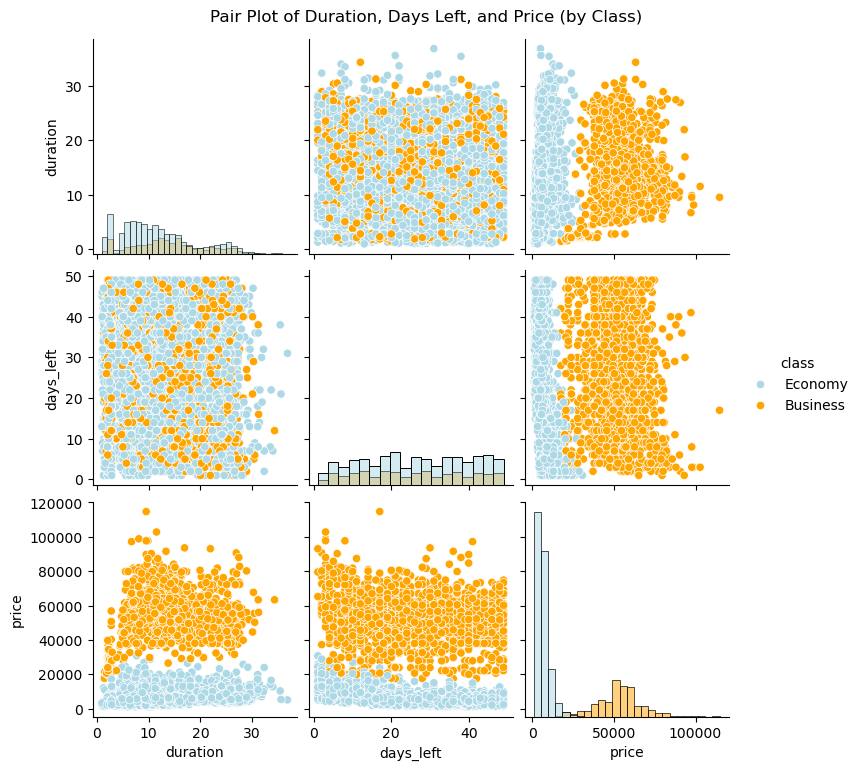

In [123]:
num_cols = ["duration", "days_left", "price"]
custom_palette = {"Economy": "lightblue", "Business": "orange"}
sns.pairplot(df[num_cols + ["class"]], hue="class", diag_kind="hist", palette=custom_palette)
plt.suptitle("Pair Plot of Duration, Days Left, and Price (by Class)", y=1.02)
plt.show()

### **INSIGHTS**
- Business class tickets are much higher in price compared to Economy, with a clear separation between the two.

- Days left does not strongly affect price fares are scattered across all days for both classes.

- Duration has little impact on price, Economy remains low and Business remains high regardless of flight time.

# **--3D SCATTER PLOT**

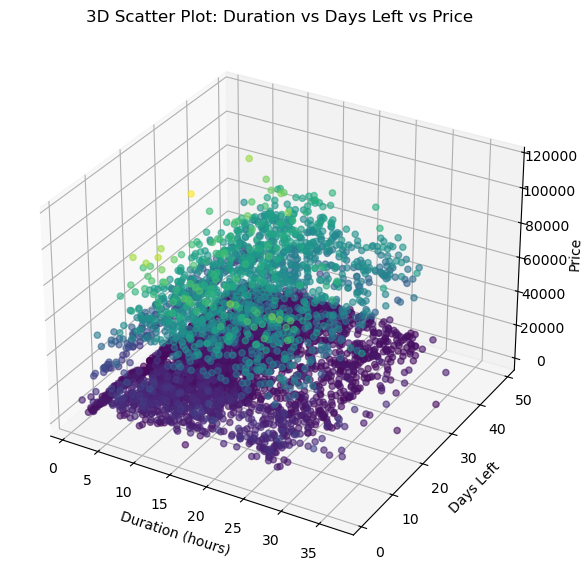

In [124]:
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df['duration'], df['days_left'], df['price'], c=df['price'], cmap='viridis', alpha=0.6)
ax.set_xlabel('Duration (hours)')
ax.set_ylabel('Days Left')
ax.set_zlabel('Price')
ax.set_title('3D Scatter Plot: Duration vs Days Left vs Price')
plt.show()

### **INSIGHTS**
- Prices clearly form two groups low (Economy) and high (Business).

- Flight duration does not strongly affect price, as both short and long flights exist in both groups.

- Days left has little impact on price, since fares are scattered across all days.

# **--KEY POINTS**
- Business class tickets are significantly more expensive than economy across all airlines.

- Economy fares show greater variation depending on booking time and stops.

- Low-cost carriers (Indigo, SpiceJet, GoAir) offer cheaper fares compared to premium airlines.

- Full-service airlines (Air India, Vistara) consistently charge higher prices with added services.

- Non-stop flights are priced higher but save time compared to connecting flights.

- Flights with stops are cheaper but involve much longer travel durations.

- Booking window (Days Left) strongly affects price—last-minute bookings are very costly.

- Advance bookings (30+ days) are the most affordable, especially in economy class.

- Departure time influences fares morning flights are slightly more expensive than evening/night flights.

- Outliers in prices exist, mostly due to urgent, last-minute business class bookings, reflecting dynamic pricing strategies.

# **^OVERALL INSIGHTS**


 **1.Pricing Structure:** Business class fares are consistently and significantly higher than economy class across all airlines. While economy class shows wider price variation depending on booking time and stops, business class fares remain at the premium end regardless of these factors.

 **2.Effect of Airlines:** Low-cost carriers (such as Indigo, SpiceJet, and GoAir) offered more competitive prices compared to full-service carriers (like Air India and Vistara). This reflects the difference in service models and passenger segments targeted. Premium airlines charge higher fares but often justify this with additional in-flight services.

**3.Impact of Stops and Duration:** Non-stop flights are preferred for their convenience and shorter travel time, but they come at a higher price. On the other hand, 1-stop and 2+ stop flights are cheaper but significantly increase total duration, highlighting a trade-off between cost and time.

 **4.Days Left Before Departure:** One of the strongest factors influencing price is the booking window. Last-minute bookings (within 0–7 days) are considerably more expensive, while advance bookings (30+ days) are much cheaper. This aligns with airline revenue management strategies to maximize profit from urgent travelers.

 **5.Departure Time Influence:** Morning flights tend to be priced slightly higher than evening or night flights, reflecting demand from business travelers who prefer early travel.

 **6.Outliers in Prices:** Extreme high fares exist in the dataset, especially for last-minute business class bookings. These outliers are genuine cases and highlight how drastically fares can surge in certain scenarios.

# **^CONCLUSION**
- This project highlights that airline ticket prices are influenced by multiple factors including airline type, class, stops, duration, booking window, and departure time.
-  Business class fares are consistently higher, while economy fares vary widely depending on booking patterns.
-   Non-stop flights, though costly, save travel time, whereas flights with stops are cheaper but longer.
-    Booking window plays the most crucial role, with last-minute tickets being very expensive and advance bookings offering the best deals.
-    Outliers such as high-priced last-minute business class tickets reflect dynamic pricing strategies.
- Overall, the findings provide insights for both travelers and airlines in decision-making.